# Logistic Regression

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score


features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

train = pd.read_csv('data/splits/train.csv')
val = pd.read_csv('data/splits/val.csv')
test = pd.read_csv('data/splits/test.csv')

X_train, y_train = train[features], train['genre_group']
X_val, y_val = val[features], val['genre_group']
X_test, y_test = test[features], test['genre_group']

print(len(train), len(val), len(test))  # should be roughly 80 / 10 / 10

68633 8579 8580


### using 'balanced' class weight

In [2]:
# scaling training data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)           # reuse train's mean/std
X_test_s = scaler.transform(X_test)

model = LogisticRegression(class_weight='balanced', max_iter=2000)
model.fit(X_train_s, y_train)

pred = model.predict(X_val_s)
print(classification_report(y_val, pred))

                      precision    recall  f1-score   support

chill_jazz_classical       0.56      0.48      0.52      1038
             country       0.16      0.47      0.24       293
    electronic_dance       0.64      0.48      0.55      1932
          hiphop_rnb       0.12      0.19      0.15       385
          indie_folk       0.11      0.39      0.18       251
               latin       0.43      0.36      0.39       917
                 pop       0.22      0.05      0.08      1096
              reggae       0.08      0.48      0.13       194
          rock_metal       0.51      0.46      0.48      1684
               world       0.22      0.06      0.10       789

            accuracy                           0.35      8579
           macro avg       0.31      0.34      0.28      8579
        weighted avg       0.42      0.35      0.37      8579



### using unbalanced class weights

In [3]:
# scaling training data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)           # reuse train's mean/std
X_test_s = scaler.transform(X_test)

model = LogisticRegression(class_weight=None, max_iter=2000)
model.fit(X_train_s, y_train)

pred = model.predict(X_val_s)
print(classification_report(y_val, pred))

                      precision    recall  f1-score   support

chill_jazz_classical       0.46      0.57      0.51      1038
             country       0.34      0.13      0.19       293
    electronic_dance       0.48      0.72      0.57      1932
          hiphop_rnb       0.39      0.02      0.03       385
          indie_folk       0.00      0.00      0.00       251
               latin       0.35      0.46      0.40       917
                 pop       0.23      0.13      0.17      1096
              reggae       0.07      0.01      0.01       194
          rock_metal       0.40      0.56      0.47      1684
               world       0.27      0.02      0.04       789

            accuracy                           0.41      8579
           macro avg       0.30      0.26      0.24      8579
        weighted avg       0.36      0.41      0.36      8579



It's better to use unbalanced

### comparing C (regularization) F1 scores

In [4]:
for C in [0.01, 0.1, 1, 10]:
    model.set_params(C=C)
    model.fit(X_train_s, y_train)
    score = f1_score(y_val, model.predict(X_val_s), average='macro')
    print(f"C={C:<5} val macro-F1 = {score:.3f}")

C=0.01  val macro-F1 = 0.235
C=0.1   val macro-F1 = 0.240
C=1     val macro-F1 = 0.240
C=10    val macro-F1 = 0.240


C=1 (default) seems to have the higher scores. Will keep C as C=1 (default)

### checking features and their coefficients

In [5]:
coefs = pd.DataFrame(model.coef_, index=model.classes_, columns=features)
coefs

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
chill_jazz_classical,-0.280075,-0.280983,-0.466472,0.406054,0.266385,0.628564,0.071495,-0.219138,-0.131346,-0.260824
country,-0.346850,-0.412632,-0.155911,-2.516734,0.290654,-0.059258,0.060318,0.680755,0.131660,-0.525465
electronic_dance,0.634744,0.499467,-0.163486,0.259936,-0.702304,0.802759,-0.081511,-0.482388,0.146330,0.140145
hiphop_rnb,0.350445,-0.622989,0.855460,0.435023,-0.097627,-0.359116,0.142224,-0.205794,-0.035468,0.230989
indie_folk,-0.017527,-0.421411,0.124438,-0.056472,0.367291,-0.405527,-0.258529,-0.166463,0.057096,0.168627
latin,0.185655,0.172646,0.328665,0.173568,0.728684,-0.375161,0.385019,0.413761,0.064541,0.176993
pop,-0.148747,0.341042,-0.133532,0.076275,0.188391,-0.000441,-0.112420,-0.176002,0.113431,0.090681
reggae,0.383971,0.005649,0.394092,0.589429,-0.544967,-0.874025,0.010031,0.489940,-0.112323,-0.053969
rock_metal,-0.718676,0.534732,-0.327516,0.221746,-0.438003,0.317515,-0.107370,-0.056038,-0.125140,-0.132960
world,-0.042940,0.184479,-0.455739,0.411174,-0.058504,0.324691,-0.109257,-0.278634,-0.108781,0.165782


speechiness         0.514641
instrumentalness    0.414706
acousticness        0.368281
energy              0.347603
loudness            0.340531
valence             0.316891
danceability        0.310963
duration_ms         0.194644
liveness            0.133817
tempo               0.102612
dtype: float64


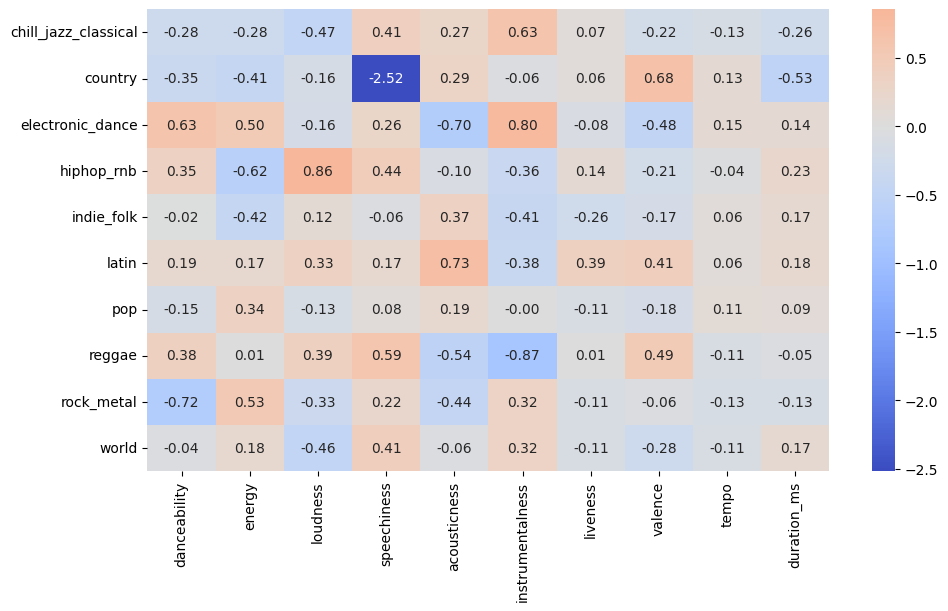

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print(coefs.abs().mean().sort_values(ascending=False))

plt.figure(figsize=(11, 6))
sns.heatmap(coefs, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

Would say it's better to keep all features to have more data to determine genre

# Results

In [7]:
# scaling training data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)           # reuse train's mean/std
X_test_s = scaler.transform(X_test)

model = LogisticRegression(class_weight=None, max_iter=2000)
model.fit(X_train_s, y_train)

pred = model.predict(X_val_s)
print(classification_report(y_val, pred))

                      precision    recall  f1-score   support

chill_jazz_classical       0.46      0.57      0.51      1038
             country       0.34      0.13      0.19       293
    electronic_dance       0.48      0.72      0.57      1932
          hiphop_rnb       0.39      0.02      0.03       385
          indie_folk       0.00      0.00      0.00       251
               latin       0.35      0.46      0.40       917
                 pop       0.23      0.13      0.17      1096
              reggae       0.07      0.01      0.01       194
          rock_metal       0.40      0.56      0.47      1684
               world       0.27      0.02      0.04       789

            accuracy                           0.41      8579
           macro avg       0.30      0.26      0.24      8579
        weighted avg       0.36      0.41      0.36      8579



In [8]:
print(classification_report(y_test, model.predict(X_test_s)))

                      precision    recall  f1-score   support

chill_jazz_classical       0.47      0.56      0.51      1038
             country       0.32      0.12      0.17       292
    electronic_dance       0.47      0.72      0.57      1932
          hiphop_rnb       0.34      0.03      0.05       385
          indie_folk       0.75      0.01      0.02       250
               latin       0.37      0.51      0.43       918
                 pop       0.25      0.15      0.19      1097
              reggae       0.19      0.03      0.05       194
          rock_metal       0.43      0.56      0.49      1685
               world       0.23      0.02      0.04       789

            accuracy                           0.42      8580
           macro avg       0.38      0.27      0.25      8580
        weighted avg       0.39      0.42      0.37      8580

